# experiment_3 — 합성 + 실물(real_raw) 학습, 실물 val로 고르는 학습 설정 비교

| 항목 | 내용 |
| --- | --- |
| 목적 | 합성 데이터로 학습할 때 **무엇이 실물 성능에 도움이 되는지** 찾기 (스케줄 · 증강 · 진짜 batch · 입력 크기 · freeze) |
| 학습 데이터 | 합성 `turtle_ninja_split_s0_shape4` train 400장 + **실물 `archive/real_raw` 중 확인 끝난 사진** (팀원 영상 프레임, `review_labels.py`로 확인한 것만) |
| 클래스 | **5클래스** 0 qr · 1 puck_cyl · 2 puck_box · 3 signal_tower · 4 barcode (바코드는 실물 라벨에서만 배움) |
| 모델 고르기 | **실물 val 23장** (`real_split5/val`) mAP50을 2 epoch마다 채점 → 최고 epoch를 `best_real.pt`로 저장 |
| 일찍 멈추기 | 실물 val mAP50이 `REAL_PATIENCE` epoch 동안 안 오르면 멈춤 (합성 val 기준 patience는 끔) |
| 최종 점수 | **실물 test 26장** (`real_split5/test`) — 마지막에 한 번만. conf 0.5 기준 맞춤·놓침·헛것도 계산 |
| batch | 모든 실험 `nbs = batch` → batch 8은 8장마다, 16은 16장마다 한 번씩 가중치를 고침 (experiment_2는 nbs=64라 batch 차이가 없었음) |
| 결과 저장 | archive `results/<RUN_ID>/` (레포에 안 쌓음) |

**실험 7개 — 기준 C에서 한 가지씩만 바꿈** (A~F는 합성 + 실물, S만 합성만)

| 실험 | batch | 스케줄 | 증강 | 그 외 | 알고 싶은 것 |
| --- | --- | --- | --- | --- | --- |
| A | 16 | linear | 기본 | | experiment_2와 같은 조건(진짜 batch 16)의 기준선 |
| B | 16 | cosine | 기본 | | linear 대 cosine (A와 비교) |
| C | 16 | cosine | 강하게 | | 증강 효과 (B와 비교) ← 기준 |
| D | 8 | cosine | 강하게 | | 진짜 batch 효과 (C와 비교) |
| E | 16 | cosine | 강하게 | imgsz 960 | 입력 크기 (C와 비교) |
| F | 16 | cosine | 강하게 | freeze 10 | 사전학습 앞부분 고정 (C와 비교) |
| S | 16 | cosine | 강하게 | **합성만** | 실물 학습 데이터 효과 (C와 비교) |

**실행 (오래 걸려요: 한 개 최대 약 1시간 × 7)** — 터미널에서, 노트북은 에디터에서 닫은 채로:
```bash
cd ~/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive
~/pa-course/.venv-yolo/bin/jupyter nbconvert --to notebook --execute --inplace \
    --ExecutePreprocessor.timeout=-1 experiment_3.ipynb
```
- 실험 하나 끝날 때마다 `runs.json`에 저장돼서, 중간에 멈춰도 끝난 결과는 남아요.
- 일부만 돌리려면 0번 셀의 `RUN_ONLY`에 이름을 적어요 (예: `["C", "E"]`).
- 진행 상황: `tail -f <EXP_DIR>/run.log`

**셀 순서**: 0 설정 → 1 로그 → 2 환경 → 3 데이터 확인 → 4 사전학습 가중치 → 5 학습·평가 함수 → 6 실행 → 7 비교 → 8 요약

## 0. 설정 — 실험마다 여기만 바꾸기

In [1]:
from pathlib import Path
from datetime import datetime

EXP_NAME = "experiment_3"
RUN_ID = f"{EXP_NAME}_{datetime.now():%Y%m%d_%H%M%S}"     # 다시 돌려도 이전 기록을 덮어쓰지 않음

HOME = Path.home()
REPO = HOME / "바탕화면/git/Project2_Turtle_Ninja"                         # 데이터셋·사전학습 가중치 (읽기만)
ARCH = HOME / "바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive"   # 결과 저장
SIM_DATA = REPO / "yolo/datasets/turtle_ninja_split_s0_shape4/data.yaml"      # 합성 train 400 / val 50 / test 50
REAL_DATA = REPO / "yolo/datasets/real_split5/data.yaml"                      # 실물 val 23 / test 26 (5클래스, 바코드 포함)
REAL_RAW = ARCH / "real_raw"                    # 실물 학습용 (사진 옆 .txt, review_labels.py로 확인)
REAL_RAW_ONLY_REVIEWED = True                   # True: 확인 끝난 사진만 학습에 씀 ('?' 남은 사진도 제외)
NAMES = {0: "qr", 1: "puck_cyl", 2: "puck_box", 3: "signal_tower", 4: "barcode"}
PRETRAINED = REPO / "yolo/models/yolo26n.pt"

PROJECT = ARCH / "results"
EXP_DIR = PROJECT / RUN_ID

CONF = 0.5              # 맞춤·놓침·헛것 셀 때 기준 = planning 기준 (0.5 미만은 버림)
REAL_EVAL_EVERY = 2     # 실물 val 채점 간격 (epoch)
REAL_PATIENCE = 50      # 실물 val mAP50이 이만큼 안 오르면 멈춤

BASE_CFG = dict(
    epochs=300,
    patience=300,         # 합성 val 기준 조기 종료는 끔 (실물 val로 멈춤)
    imgsz=1280,
    device=0,
    workers=8,
    seed=0,
    deterministic=True,
    optimizer="SGD",      # auto면 lr0를 무시함 → 반드시 SGD
    lr0=0.001,            # 시작 lr
    lrf=0.1,              # 끝 lr = 0.0001
    momentum=0.937,
    warmup_epochs=3,
    warmup_bias_lr=0.01,
    warmup_momentum=0.8,
    close_mosaic=10,
    pretrained=True,
    plots=True,
    save=True,
    verbose=True,
)
AUG_BASE = dict(hsv_h=0.015)                      # experiment_2와 같음 (나머지는 Ultralytics 기본값)
AUG_STRONG = dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.5,   # 색·밝기
                  scale=0.7,                            # 크기 (멀리·가까이)
                  degrees=5.0, translate=0.2,           # 기울기·이동
                  mixup=0.1, copy_paste=0.3,            # 사진 섞기·물체 붙이기
                  erasing=0.4)                          # 부분 가림

RUNS = [  # nbs는 항상 batch와 같게 (진짜 batch 비교)
    dict(name="A", batch=16, cos_lr=False, aug="base",   imgsz=1280, freeze=None, real=True, why="기준선 (experiment_2 + 진짜 batch 16)"),
    dict(name="B", batch=16, cos_lr=True,  aug="base",   imgsz=1280, freeze=None, real=True, why="linear → cosine"),
    dict(name="C", batch=16, cos_lr=True,  aug="strong", imgsz=1280, freeze=None, real=True, why="증강 강하게 (기준)"),
    dict(name="D", batch=8,  cos_lr=True,  aug="strong", imgsz=1280, freeze=None, real=True, why="진짜 batch 8"),
    dict(name="E", batch=16, cos_lr=True,  aug="strong", imgsz=960,  freeze=None, real=True, why="입력 크기 960"),
    dict(name="F", batch=16, cos_lr=True,  aug="strong", imgsz=1280, freeze=10,   real=True, why="앞 10층 고정"),
    dict(name="S", batch=16, cos_lr=True,  aug="strong", imgsz=1280, freeze=None, real=False, why="합성만 (실물 학습 없음)"),
]
RUN_ONLY = []           # 비우면 전부. 예: ["C", "E"]
RUNS = [r for r in RUNS if not RUN_ONLY or r["name"] in RUN_ONLY]

def train_cfg(r):
    cfg = dict(BASE_CFG, batch=r["batch"], nbs=r["batch"], cos_lr=r["cos_lr"], imgsz=r["imgsz"],
               **(AUG_STRONG if r["aug"] == "strong" else AUG_BASE))
    if r["freeze"]:
        cfg["freeze"] = r["freeze"]
    return cfg

print("RUN_ID  :", RUN_ID)
print("EXP_DIR :", EXP_DIR)
for r in RUNS:
    print(f"  {r['name']}: batch {r['batch']} (nbs {r['batch']}) | {'cosine' if r['cos_lr'] else 'linear'} | 증강 {r['aug']} | "
          f"imgsz {r['imgsz']} | freeze {r['freeze']} | 실물 학습 {r['real']} — {r['why']}")

RUN_ID  : experiment_3_20261024_195441
EXP_DIR : /home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441
  A: batch 16 (nbs 16) | linear | 증강 base | imgsz 1280 | freeze None | 실물 학습 True — 기준선 (experiment_2 + 진짜 batch 16)
  B: batch 16 (nbs 16) | cosine | 증강 base | imgsz 1280 | freeze None | 실물 학습 True — linear → cosine
  C: batch 16 (nbs 16) | cosine | 증강 strong | imgsz 1280 | freeze None | 실물 학습 True — 증강 강하게 (기준)
  D: batch 8 (nbs 8) | cosine | 증강 strong | imgsz 1280 | freeze None | 실물 학습 True — 진짜 batch 8
  E: batch 16 (nbs 16) | cosine | 증강 strong | imgsz 960 | freeze None | 실물 학습 True — 입력 크기 960
  F: batch 16 (nbs 16) | cosine | 증강 strong | imgsz 1280 | freeze 10 | 실물 학습 True — 앞 10층 고정
  S: batch 16 (nbs 16) | cosine | 증강 strong | imgsz 1280 | freeze None | 실물 학습 False — 합성만 (실물 학습 없음)


## 1. 로그 시작 — 이 셀 이후의 모든 출력이 `run.log`에도 저장돼요

In [2]:
import sys, json

PROJECT.mkdir(parents=True, exist_ok=True)
gi = PROJECT / ".gitignore"
if not gi.exists():   # archive는 TIL git 안 → 가중치·결과가 커밋되지 않게
    gi.write_text("# 실험 결과(가중치·이미지·로그)는 커밋하지 않음\n*\n", encoding="utf-8")
EXP_DIR.mkdir(parents=True, exist_ok=False)
LOG_PATH = EXP_DIR / "run.log"

class Tee:
    """화면 출력과 run.log에 동시에 쓰기."""
    def __init__(self, stream, path):
        self.stream, self.file = stream, open(path, "a", encoding="utf-8", buffering=1)
    def write(self, s):
        self.stream.write(s); self.file.write(s); return len(s)
    def flush(self):
        self.stream.flush(); self.file.flush()
    def __getattr__(self, name):
        return getattr(self.stream, name)

if not isinstance(sys.stdout, Tee):
    sys.stdout = Tee(sys.stdout, LOG_PATH)
    sys.stderr = Tee(sys.stderr, LOG_PATH)

def save_json(name, obj, folder=None):
    p = (folder or EXP_DIR) / name
    p.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    return p

save_json("config.json", dict(RUN_ID=RUN_ID, SIM_DATA=SIM_DATA, REAL_DATA=REAL_DATA, REAL_RAW=REAL_RAW,
                              REAL_RAW_ONLY_REVIEWED=REAL_RAW_ONLY_REVIEWED, NAMES=NAMES, PRETRAINED=PRETRAINED,
                              BASE_CFG=BASE_CFG, AUG_BASE=AUG_BASE, AUG_STRONG=AUG_STRONG, RUNS=RUNS,
                              CONF=CONF, REAL_EVAL_EVERY=REAL_EVAL_EVERY, REAL_PATIENCE=REAL_PATIENCE,
                              model_selection="max real val mAP50"))
print(f"[{datetime.now():%F %T}] 로그 시작 → {LOG_PATH}")

[2026-10-24 19:54:41] 로그 시작 → /home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441/run.log


## 2. 환경 기록 — 버전·GPU·git 상태

In [3]:
import platform, subprocess
import torch, ultralytics

def git(*args):
    try:
        return subprocess.run(["git", "-C", str(REPO), *args], capture_output=True, text=True).stdout.strip()
    except Exception as e:
        return f"error: {e}"

env = dict(time=datetime.now().isoformat(timespec="seconds"), python=sys.version.split()[0],
           platform=platform.platform(), torch=torch.__version__, cuda_available=torch.cuda.is_available(),
           cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
           ultralytics=ultralytics.__version__, git_branch=git("rev-parse", "--abbrev-ref", "HEAD"),
           git_commit=git("rev-parse", "--short", "HEAD"))
for k, v in env.items():
    print(f"{k:15s} {v}")
save_json("env.json", env)
assert env["cuda_available"], "GPU가 안 잡혀요. 커널이 .venv-yolo인지 확인하세요."

time            2026-10-24T19:54:42
python          3.12.3
platform        Linux-7.0.0-38-generic-x86_64-with-glibc2.39
torch           2.11.0+cu128
cuda_available  True
cuda            12.8
gpu             NVIDIA GeForce RTX 5060 Laptop GPU
ultralytics     8.4.183
git_branch      main
git_commit      f872159


## 3. 데이터 확인 — 합성(학습)과 실물(val·test)

- 합성: 지난 실험과 같은 split 폴더를 그대로 써요 (새로 나누지 않음).
- 실물 val/test: 10/24에 촬영 묶음 단위로 나눈 `real_split5` (val 14~36번 23장 / test 나머지 26장, 바코드 포함).
- 실물 학습: `archive/real_raw`에서 확인 끝난 사진만 골라 합성 train과 합친 목록(`train_list_real.txt`)을 만들어요. val/test와는 다른 촬영이라 섞이지 않아요.
- 합성 라벨은 0~3번만 써서 5클래스에 그대로 들어가요.
- 클래스 이름이 서로 다르면 여기서 멈춰요.

In [4]:
import yaml
from collections import Counter

def load_yaml(p):
    return yaml.safe_load(Path(p).read_text(encoding="utf-8"))

def names_of(y):
    n = y["names"]
    return {int(k): v for k, v in n.items()} if isinstance(n, dict) else dict(enumerate(n))

sim_y, real_y = load_yaml(SIM_DATA), load_yaml(REAL_DATA)
assert names_of(real_y) == NAMES, names_of(real_y)
assert all(NAMES[k] == v for k, v in names_of(sim_y).items()), names_of(sim_y)   # 합성 0~3 = 5클래스의 0~3
print("클래스:", NAMES)

def count(root, rel):
    img_dir = Path(root) / rel
    lbl_dir = Path(str(img_dir).replace("/images", "/labels"))
    imgs = sorted(p for p in img_dir.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
    cnt = Counter()
    for p in imgs:
        f = lbl_dir / (p.stem + ".txt")
        if f.exists():
            cnt.update(int(l.split()[0]) for l in f.read_text().splitlines() if l.strip())
    return imgs, {NAMES[c]: cnt.get(c, 0) for c in NAMES}

stats = {}
for tag, y, split in [("sim train", sim_y, "train"), ("sim val", sim_y, "val"), ("sim test", sim_y, "test"),
                      ("real val", real_y, "val"), ("real test", real_y, "test")]:
    imgs, per = count(y["path"], y[split])
    stats[tag] = dict(images=len(imgs), per_class=per)
    print(f"{tag:10s} {len(imgs):4d}장  " + "  ".join(f"{k} {v}" for k, v in per.items()))
REAL_TEST_IMGS, _ = count(real_y["path"], real_y["test"])

# 실물 학습 사진: 확인 끝난 것만 (라벨은 사진 옆 .txt)
import os
review = json.loads((REAL_RAW / "_review.json").read_text()) if (REAL_RAW / "_review.json").exists() else {}
raw_imgs = sorted(p for p in REAL_RAW.rglob("*") if p.suffix.lower() in (".jpg", ".jpeg", ".png") and p.name != "contact.jpg")
real_train = []
for p in raw_imgs:
    info = review.get(str(p.relative_to(REAL_RAW)), {})
    if not p.with_suffix(".txt").exists():
        continue
    if REAL_RAW_ONLY_REVIEWED and (not info.get("reviewed") or info.get("unchecked")):
        continue
    real_train.append(p)
cnt = Counter()
for p in real_train:
    cnt.update(int(l.split()[0]) for l in p.with_suffix(".txt").read_text().splitlines() if l.strip())
stats["real train"] = dict(images=len(real_train), per_class={NAMES[c]: cnt.get(c, 0) for c in NAMES})
print(f"real train {len(real_train):4d}장 (real_raw {len(raw_imgs)}장 중 확인 끝난 것)  "
      + "  ".join(f"{k} {v}" for k, v in stats['real train']['per_class'].items()))
if not real_train:
    print("⚠ 확인 끝난 real_raw 사진이 없어요 → 실물 학습 실험도 합성만으로 학습돼요. review_labels.py로 먼저 확인하세요.")

sim_root = Path(sim_y["path"])
sim_train = sorted(p for p in (sim_root / sim_y["train"]).iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
lists = {True: EXP_DIR / "train_list_real.txt", False: EXP_DIR / "train_list_sim.txt"}
lists[True].write_text("\n".join(str(p) for p in sim_train + real_train) + "\n")
lists[False].write_text("\n".join(str(p) for p in sim_train) + "\n")
TRAIN_YAML = {}
for use_real, lst in lists.items():
    y = EXP_DIR / f"data_train_{'real' if use_real else 'sim'}.yaml"
    y.write_text(yaml.safe_dump(dict(train=str(lst), val=str(sim_root / sim_y["val"]), names=NAMES), allow_unicode=True, sort_keys=False))
    TRAIN_YAML[use_real] = y
SIM5_DATA = EXP_DIR / "data_sim5.yaml"     # 합성 test 평가용 (5클래스 이름)
SIM5_DATA.write_text(yaml.safe_dump(dict(path=str(sim_root), train=sim_y["train"], val=sim_y["val"], test=sim_y["test"], names=NAMES),
                                    allow_unicode=True, sort_keys=False))
print("학습 목록:", {("합성+실물" if k else "합성만"): sum(1 for _ in v.open()) for k, v in lists.items()})
save_json("real_train_files.json", [str(p) for p in real_train])
save_json("dataset_stats.json", stats)
if stats["real val"]["per_class"]["signal_tower"] == 0:
    print("⚠ 실물 val에 신호등이 없어요 → 신호등은 모델 고르기에 반영 안 됨 (test에서만 확인)")

클래스: {0: 'qr', 1: 'puck_cyl', 2: 'puck_box', 3: 'signal_tower', 4: 'barcode'}
sim train   400장  qr 0  puck_cyl 457  puck_box 475  signal_tower 170  barcode 0
sim val      50장  qr 0  puck_cyl 41  puck_box 66  signal_tower 25  barcode 0
sim test     50장  qr 0  puck_cyl 68  puck_box 58  signal_tower 23  barcode 0
real val     23장  qr 1  puck_cyl 16  puck_box 19  signal_tower 0  barcode 12
real test    26장  qr 0  puck_cyl 17  puck_box 17  signal_tower 3  barcode 13
real train  174장 (real_raw 359장 중 확인 끝난 것)  qr 124  puck_cyl 120  puck_box 73  signal_tower 72  barcode 58
학습 목록: {'합성+실물': 574, '합성만': 400}
⚠ 실물 val에 신호등이 없어요 → 신호등은 모델 고르기에 반영 안 됨 (test에서만 확인)


## 4. 사전학습 가중치 — `yolo26n.pt` (모든 실험이 여기서 새로 시작)

In [5]:
import hashlib
from ultralytics import YOLO

assert PRETRAINED.exists(), f"사전학습 가중치가 없어요: {PRETRAINED}"
sha = hashlib.sha256(PRETRAINED.read_bytes()).hexdigest()
print(PRETRAINED, f"{PRETRAINED.stat().st_size / 1e6:.1f} MB", "sha256", sha[:12])
save_json("pretrained.json", dict(path=PRETRAINED, sha256=sha))

/home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt 5.5 MB sha256 9b09cc8bf347


PosixPath('/home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441/pretrained.json')

## 5. 학습·평가 함수

실험 하나마다:
1. `yolo26n.pt`에서 새로 학습 (`nbs = batch`)
2. `REAL_EVAL_EVERY` epoch마다 **실물 val** mAP50 채점 → 최고면 `best_real.pt`로 저장, `real_val.csv`에 기록
3. 실물 val이 `REAL_PATIENCE` epoch 동안 안 오르면 멈춤
4. `best_real.pt`로 **실물 test**, 실물 val, 합성 test 평가 + conf 0.5 기준 실물 test 사진별 맞춤·놓침·헛것과 정답|예측 그림
5. 메모리 부족(OOM)이면 기록하고 다음 실험으로

In [6]:
import time, gc, csv, math, shutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

COLORS = ["#e6194b", "#3cb44b", "#ffe119", "#4363d8", "#f58231"]

def evaluate(weights, data_yaml, split, imgsz, out_dir, tag, plots=True):
    m = weights.val(data=str(data_yaml), split=split, imgsz=imgsz, batch=8, device=BASE_CFG["device"],
                    project=str(out_dir), name=f"eval_{tag}", exist_ok=True, plots=plots, verbose=False)
    per_class = {}
    for k, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(k)
        per_class[NAMES[int(c)]] = dict(P=round(float(p), 4), R=round(float(r), 4), mAP50=round(float(ap50), 4))
    return dict(P=round(float(m.box.mp), 4), R=round(float(m.box.mr), 4),
                mAP50=round(float(m.box.map50), 4), mAP50_95=round(float(m.box.map), 4), per_class=per_class)

def iou(a, b):
    x0, y0, x1, y1 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x1 - x0) * max(0, y1 - y0)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def gt_boxes(lbl, W, H):
    out = []
    if lbl.exists():
        for l in lbl.read_text().splitlines():
            if l.strip():
                c, cx, cy, bw, bh = int(l.split()[0]), *map(float, l.split()[1:])
                out.append((c, [(cx - bw / 2) * W, (cy - bh / 2) * H, (cx + bw / 2) * W, (cy + bh / 2) * H]))
    return out

def real_counts(weights, imgsz, run_dir):
    """실물 test 사진별 맞춤(TP)·놓침(FN)·헛것(FP): conf ≥ CONF, IoU ≥ 0.5, 같은 클래스. 정답|예측 그림 저장."""
    vis = run_dir / "real_test_vis"; vis.mkdir(exist_ok=True)
    rows_ = []
    preds = weights.predict([str(p) for p in REAL_TEST_IMGS], conf=CONF, imgsz=imgsz, device=BASE_CFG["device"], verbose=False)
    for p, r in zip(REAL_TEST_IMGS, preds):
        H, W = r.orig_shape
        lbl = Path(str(p.parent).replace("/images", "/labels")) / (p.stem + ".txt")
        gts = gt_boxes(lbl, W, H)
        pds = [(int(b.cls), b.xyxy[0].tolist(), float(b.conf)) for b in r.boxes]
        used, tp = set(), 0
        for c, box, _ in sorted(pds, key=lambda x: -x[2]):
            cand = [(iou(box, g[1]), j) for j, g in enumerate(gts) if j not in used and g[0] == c]
            if cand and max(cand)[0] >= 0.5:
                used.add(max(cand)[1]); tp += 1
        rows_.append(dict(image=p.name, gt=len(gts), pred=len(pds), TP=tp, FN=len(gts) - tp, FP=len(pds) - tp,
                          pred_classes=" ".join(f"{NAMES[c]}:{s:.2f}" for c, _, s in pds)))
        gt_img = Image.open(p).convert("RGB"); d = ImageDraw.Draw(gt_img)
        for c, b in gts:
            d.rectangle(b, outline=COLORS[c % 5], width=3); d.text((b[0], max(0, b[1] - 12)), NAMES[c], fill=COLORS[c % 5])
        both = Image.new("RGB", (W * 2 + 20, H), "white"); both.paste(gt_img, (0, 0))
        both.paste(Image.fromarray(r.plot()[..., ::-1]), (W + 20, 0))
        both.resize((W, H // 2)).save(vis / f"{p.stem}_gt_vs_pred.jpg", quality=85)
    with open(run_dir / "real_test_per_image.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(rows_[0])); w.writeheader(); w.writerows(rows_)
    return dict(images=len(rows_), TP=sum(x["TP"] for x in rows_), FN=sum(x["FN"] for x in rows_), FP=sum(x["FP"] for x in rows_))

def plot_run(rows, real_hist, run_dir, r, best_ep):
    ep = [int(float(x["epoch"])) for x in rows]
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    for k, col in (("box_loss", "#4363d8"), ("cls_loss", "#e6194b")):
        if f"train/{k}" in rows[0] and f"val/{k}" in rows[0]:
            ax[0].plot(ep, [float(x[f"train/{k}"]) for x in rows], color=col, label=f"train {k}")
            ax[0].plot(ep, [float(x[f"val/{k}"]) for x in rows], color=col, ls="--", label=f"sim val {k}")
    ax[0].set_yscale("log"); ax[0].set_title(f"{r['name']}: loss"); ax[0].legend(fontsize=8)
    ax[1].plot(ep, [float(x["lr/pg0"]) for x in rows]); ax[1].set_title("actual lr (pg0)")
    ax[2].plot(ep, [float(x["metrics/mAP50(B)"]) for x in rows], color="#bbbbbb", label="sim val mAP50")
    if real_hist:
        ax[2].plot([h["epoch"] for h in real_hist], [h["mAP50"] for h in real_hist], color="#4363d8", marker=".", label="real val mAP50")
    ax[2].set_ylim(0, 1); ax[2].set_title("mAP50: sim val vs real val"); ax[2].legend()
    for a in ax:
        if best_ep: a.axvline(best_ep, color="gray", ls=":")
        a.set_xlabel("epoch"); a.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(run_dir / "curves.png", dpi=110); plt.show()

def run_one(r):
    name = r["name"]; run_dir = EXP_DIR / name; cfg = train_cfg(r)
    best_path = run_dir / "weights" / "best_real.pt"
    best = {"mAP50": -1.0, "epoch": None}
    real_hist = []
    print(f"\n{'=' * 80}\n[{datetime.now():%H:%M:%S}] 실험 {name} 시작 — {r['why']}\n"
          f"학습 데이터 {'합성+실물' if r['real'] else '합성만'} | batch {cfg['batch']} nbs {cfg['nbs']} | {'cosine' if cfg['cos_lr'] else 'linear'} | 증강 {r['aug']} | imgsz {cfg['imgsz']} | freeze {cfg.get('freeze')}\n{'=' * 80}")

    def on_epoch_end(trainer):
        ep = int(trainer.epoch) + 1
        final = ep >= trainer.epochs
        if (ep % REAL_EVAL_EVERY and not final) or not Path(trainer.last).exists():
            return
        m = YOLO(str(trainer.last)).val(data=str(REAL_DATA), split="val", imgsz=cfg["imgsz"], batch=8,
                                        device=BASE_CFG["device"], plots=False, verbose=False,
                                        project=str(run_dir), name="_real_val_tmp", exist_ok=True)
        v = float(m.box.map50)
        real_hist.append(dict(epoch=ep, mAP50=round(v, 4), P=round(float(m.box.mp), 4), R=round(float(m.box.mr), 4)))
        if v > best["mAP50"]:
            best.update(mAP50=v, epoch=ep)
            best_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(trainer.last, best_path)
            print(f"[best_real] {name} epoch {ep}: real val mAP50 {v:.4f} 저장")
        elif best["epoch"] and ep - best["epoch"] >= REAL_PATIENCE:
            print(f"[멈춤] {name}: 실물 val mAP50이 {REAL_PATIENCE} epoch 동안 안 오름 (최고 epoch {best['epoch']}, {best['mAP50']:.4f})")
            trainer.stop = True

    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model = YOLO(str(PRETRAINED)); model.add_callback("on_fit_epoch_end", on_epoch_end)
    t0 = time.time()
    try:
        model.train(data=str(TRAIN_YAML[r["real"]]), project=str(EXP_DIR), name=name, exist_ok=True, **cfg)
    except Exception as e:
        msg = str(e)
        status = "OOM" if ("out of memory" in msg.lower() or isinstance(e, torch.cuda.OutOfMemoryError)) else "error"
        print(f"⚠ 실험 {name} 중단: {status} — {msg[:300]}")
        del model; gc.collect(); torch.cuda.empty_cache()
        return dict(name=name, why=r["why"], status=status, error=msg[:300], peak_gpu_gb=round(torch.cuda.max_memory_reserved() / 1e9, 2))
    train_min = (time.time() - t0) / 60
    peak = torch.cuda.max_memory_reserved() / 1e9
    del model; gc.collect(); torch.cuda.empty_cache()
    shutil.rmtree(run_dir / "_real_val_tmp", ignore_errors=True)

    with open(run_dir / "results.csv", encoding="utf-8") as f:
        rows = [{k.strip(): v.strip() for k, v in x.items()} for x in csv.DictReader(f)]
    with open(run_dir / "real_val.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=["epoch", "mAP50", "P", "R"]); w.writeheader(); w.writerows(real_hist)
    lrs = [float(x["lr/pg0"]) for x in rows]
    print(f"학습 {train_min:.1f}분, {len(rows)} epoch, GPU 최대 {peak:.2f} GB, 실제 lr 최고 {max(lrs):.6f} / 마지막 {lrs[-1]:.6f}")
    plot_run(rows, real_hist, run_dir, r, best["epoch"])

    weights = YOLO(str(best_path))
    res = dict(name=name, why=r["why"], status="ok", real_train=r["real"], batch=cfg["batch"], schedule="cosine" if cfg["cos_lr"] else "linear",
               aug=r["aug"], imgsz=cfg["imgsz"], freeze=cfg.get("freeze"), epochs_run=len(rows),
               best_epoch=best["epoch"], best_real_val_mAP50=round(best["mAP50"], 4),
               train_min=round(train_min, 1), peak_gpu_gb=round(peak, 2), best_path=str(best_path),
               real_test=evaluate(weights, REAL_DATA, "test", cfg["imgsz"], run_dir, "real_test"),
               real_val=evaluate(weights, REAL_DATA, "val", cfg["imgsz"], run_dir, "real_val", plots=False),
               sim_test=evaluate(weights, SIM5_DATA, "test", cfg["imgsz"], run_dir, "sim_test", plots=False),
               real_test_counts=real_counts(weights, cfg["imgsz"], run_dir))
    del weights; gc.collect(); torch.cuda.empty_cache()
    save_json("run_result.json", res, folder=run_dir)
    rc = res["real_test_counts"]
    print(f"실험 {name}: 실물 test mAP50 {res['real_test']['mAP50']:.3f} | 실물 val {res['real_val']['mAP50']:.3f} | "
          f"합성 test {res['sim_test']['mAP50']:.3f} | conf {CONF}: 맞춤 {rc['TP']} 놓침 {rc['FN']} 헛것 {rc['FP']}")
    return res

## 6. 실행 — 실험마다 처음부터 학습 (오래 걸려요)


[19:54:43] 실험 A 시작 — 기준선 (experiment_2 + 진짜 batch 16)
학습 데이터 합성+실물 | batch 16 nbs 16 | linear | 증강 base | imgsz 1280 | freeze None


New https://pypi.org/project/ultralytics/8.4.185 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441/data_train_real.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt, momentum=0.937, mosaic=1.0, mu

Overriding model.yaml nc=80 with nc=5


...

              puck_box         45         66      0.995      0.955      0.991      0.931


          signal_tower         25         25      0.993          1      0.995      0.958


Speed: 1.9ms preprocess, 91.2ms inference, 0.0ms loss, 1.5ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441/A


학습 26.3분, 90 epoch, GPU 최대 7.78 GB, 실제 lr 최고 0.000992 / 마지막 0.000733


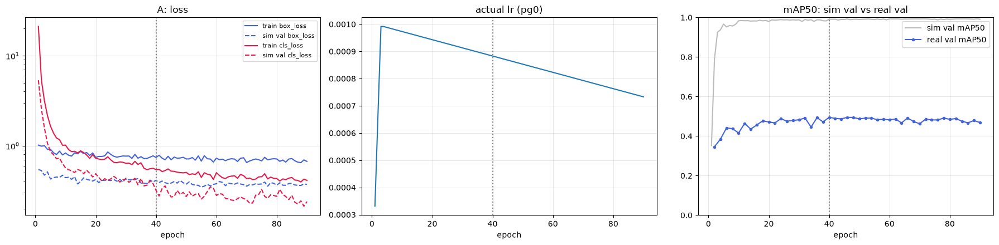

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5745.9±1077.1 MB/s, size: 347.9 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_split5/test/labels... 26 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 1.4Kit/s 0.0s

val: New cache created: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_split5/test/labels.cache


...

              puck_box         45         66          1      0.927      0.991      0.935


          signal_tower         25         25      0.994          1      0.995      0.953


Speed: 2.9ms preprocess, 51.0ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441/B


학습 25.1분, 90 epoch, GPU 최대 7.72 GB, 실제 lr 최고 0.001000 / 마지막 0.000818


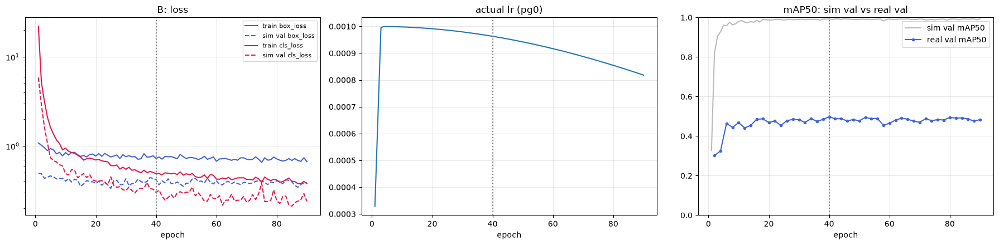

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 448.5±42.9 MB/s, size: 341.1 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_split5/test/labels.cache... 26 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 10.9Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 2.0s/it 0.6s<6.1s

...

              puck_box         45         66          1      0.938      0.991      0.893


          signal_tower         25         25      0.988          1      0.995      0.887


Speed: 5.1ms preprocess, 6.0ms inference, 0.0ms loss, 2.1ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441/C


학습 22.5분, 78 epoch, GPU 최대 7.71 GB, 실제 lr 최고 0.001000 / 마지막 0.000861


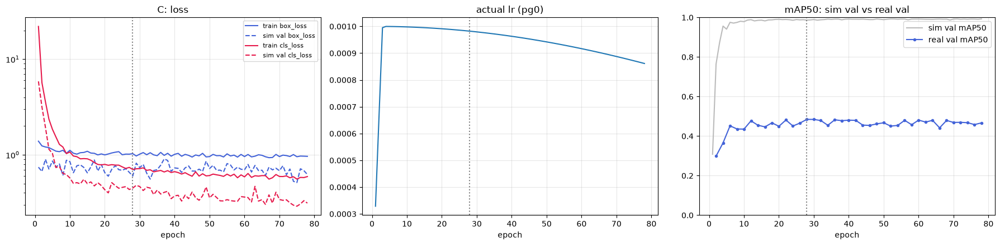

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4305.8±793.1 MB/s, size: 349.4 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_split5/test/labels.cache... 26 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 6.8Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 2.4s/it 0.7s<7.2s

...

              puck_box         45         66          1      0.926      0.992      0.932


          signal_tower         25         25      0.995          1      0.995      0.925


Speed: 5.2ms preprocess, 4.5ms inference, 0.0ms loss, 1.6ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441/D


학습 38.6분, 138 epoch, GPU 최대 6.15 GB, 실제 lr 최고 0.001000 / 마지막 0.000611


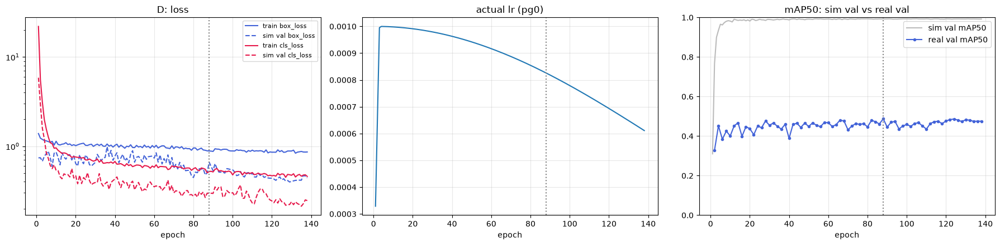

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 795.5±339.0 MB/s, size: 332.2 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_split5/test/labels.cache... 26 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 9.1Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 2.2s/it 0.6s<6.5s

...

              puck_box         45         66          1      0.928      0.993      0.922


          signal_tower         25         25      0.996          1      0.995      0.909


Speed: 1.3ms preprocess, 86.7ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441/E


학습 22.6분, 136 epoch, GPU 최대 6.57 GB, 실제 lr 최고 0.001000 / 마지막 0.000620


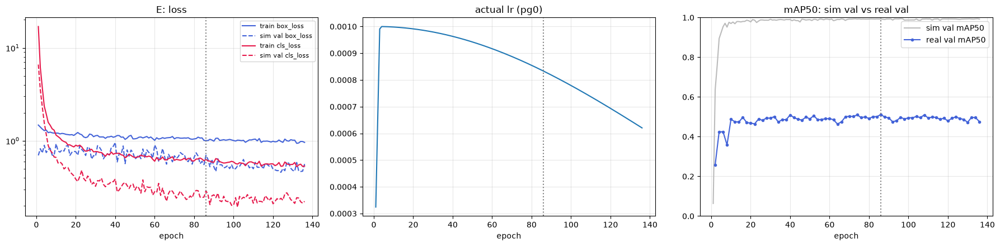

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4943.2±417.1 MB/s, size: 352.3 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_split5/test/labels.cache... 26 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 12.1Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 1.9s/it 0.6s<5.8s

...

              puck_box         45         66          1      0.924      0.992      0.867


          signal_tower         25         25      0.993          1      0.995      0.855


Speed: 0.2ms preprocess, 95.9ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441/F


학습 22.0분, 100 epoch, GPU 최대 7.77 GB, 실제 lr 최고 0.001000 / 마지막 0.000779


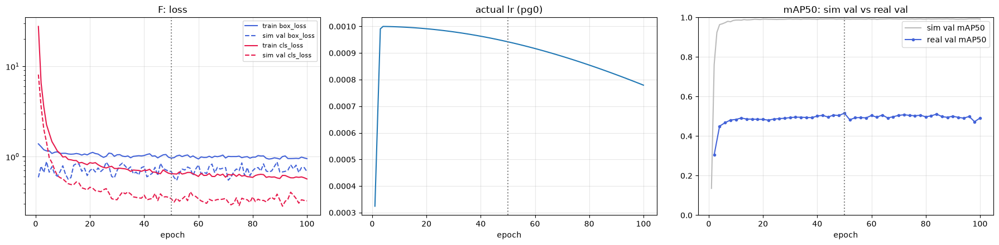

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4535.8±862.3 MB/s, size: 347.9 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_split5/test/labels.cache... 26 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 10.9Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 2.1s/it 0.6s<6.3s

...

              puck_box         45         66          1      0.869      0.992      0.932


          signal_tower         25         25      0.997          1      0.995      0.934


Speed: 4.6ms preprocess, 7.5ms inference, 0.0ms loss, 0.5ms postprocess per image


Results saved to /home/haeminkim/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/results/experiment_3_20261024_195441/S


학습 29.1분, 142 epoch, GPU 최대 7.79 GB, 실제 lr 최고 0.001000 / 마지막 0.000592


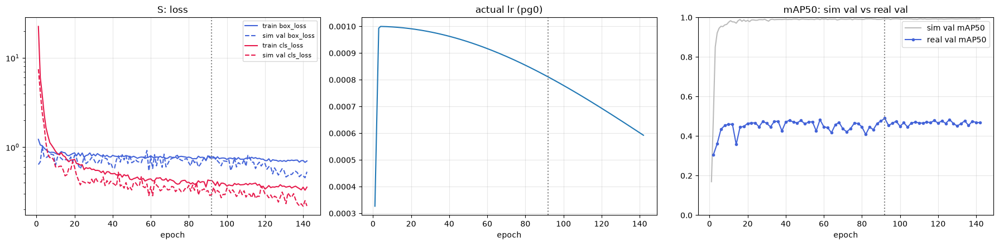

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)


YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4575.1±374.8 MB/s, size: 322.1 KB)


val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_split5/test/labels.cache... 26 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 9.9Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 2.0s/it 0.6s<6.1s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 71% ━━━━━━━━╸─── 5/7 7.7it/s 1.2s<0.3s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 5.3it/s 1.3s

                   all         50        149       0.99      0.972      0.989      0.864


Speed: 1.4ms preprocess, 5.1ms inference, 0.0ms loss, 0.9ms postprocess per image


실험 S: 실물 test mAP50 0.718 | 실물 val 0.490 | 합성 test 0.989 | conf 0.5: 맞춤 33 놓침 17 헛것 2


In [7]:
runs = {}
for r in RUNS:
    runs[r["name"]] = run_one(r)
    save_json("runs.json", runs)          # 실험 하나 끝날 때마다 저장

## 7. 비교 — 표 + 그래프

- 판단 기준: **실물 test mAP50** (모델 고를 때 안 쓴 사진). 실물 val은 모델 고르기에 썼으니 참고만.
- 비교 짝: A↔B 스케줄, B↔C 증강, C↔D batch, C↔E 입력 크기, C↔F freeze
- `comparison.csv`, `comparison.png`

,name,why,status,batch,schedule,aug,imgsz,freeze,epochs_run,best_epoch,...,puck_box,signal_tower,barcode,real_val_mAP50,sim_test_mAP50,TP,FN,FP,train_min,peak_gpu_gb
0,A,기준선 (experiment_2 + 진짜 batch 16),ok,16,linear,base,1280,NaN,90,40,...,0.9207,0.995,0.0002,0.4952,0.9827,34,16,3,26.3,7.78
1,B,linear → cosine,ok,16,cosine,base,1280,NaN,90,40,...,0.9314,0.995,0.0109,0.4977,0.9850,34,16,3,25.1,7.72
2,C,증강 강하게 (기준),ok,16,cosine,strong,1280,NaN,78,28,...,0.9176,0.995,0.0050,0.4847,0.9840,33,17,7,22.5,7.71
3,D,진짜 batch 8,ok,8,cosine,strong,1280,NaN,138,88,...,0.9687,0.995,0.0083,0.4873,0.9882,36,14,5,38.6,6.15
4,E,입력 크기 960,ok,16,cosine,strong,960,NaN,136,86,...,0.9856,0.995,0.0055,0.5114,0.9820,35,15,0,22.6,6.57
5,F,앞 10층 고정,ok,16,cosine,strong,1280,10.0,100,50,...,0.9197,0.995,0.0202,0.5161,0.9843,34,16,2,22.0,7.77
6,S,합성만 (실물 학습 없음),ok,16,cosine,strong,1280,NaN,142,92,...,0.9470,0.995,0.0000,0.4901,0.9887,33,17,2,29.1,7.79


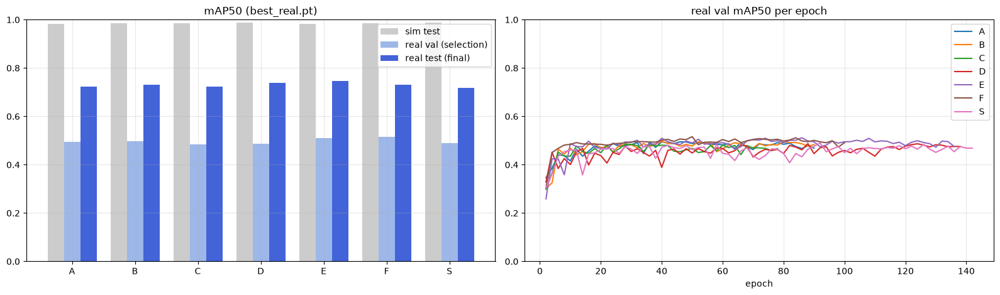

In [8]:
ok = [r for r in runs.values() if r.get("status") == "ok"]
cols = ["name", "why", "status", "batch", "schedule", "aug", "imgsz", "freeze", "epochs_run", "best_epoch",
        "real_test_mAP50", "puck_cyl", "puck_box", "signal_tower", "barcode", "real_val_mAP50", "sim_test_mAP50",
        "TP", "FN", "FP", "train_min", "peak_gpu_gb"]
table = []
for r in runs.values():
    pc = r.get("real_test", {}).get("per_class", {})
    rc = r.get("real_test_counts", {})
    table.append(dict(name=r["name"], why=r["why"], status=r["status"], batch=r.get("batch", ""), schedule=r.get("schedule", ""),
                      aug=r.get("aug", ""), imgsz=r.get("imgsz", ""), freeze=r.get("freeze", ""), epochs_run=r.get("epochs_run", ""),
                      best_epoch=r.get("best_epoch", ""), real_test_mAP50=r.get("real_test", {}).get("mAP50", ""),
                      puck_cyl=pc.get("puck_cyl", {}).get("mAP50", ""), puck_box=pc.get("puck_box", {}).get("mAP50", ""),
                      signal_tower=pc.get("signal_tower", {}).get("mAP50", ""), barcode=pc.get("barcode", {}).get("mAP50", ""),
                      real_val_mAP50=r.get("real_val", {}).get("mAP50", ""), sim_test_mAP50=r.get("sim_test", {}).get("mAP50", ""),
                      TP=rc.get("TP", ""), FN=rc.get("FN", ""), FP=rc.get("FP", ""),
                      train_min=r.get("train_min", ""), peak_gpu_gb=r.get("peak_gpu_gb", "")))
with open(EXP_DIR / "comparison.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=cols); w.writeheader(); w.writerows(table)
try:
    import pandas as pd
    display(pd.DataFrame(table)[cols])
except ImportError:
    for t in table:
        print(" | ".join(str(t[c]) for c in cols))

if ok:
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
    xs = np.arange(len(ok)); wdt = 0.26
    ax[0].bar(xs - wdt, [r["sim_test"]["mAP50"] for r in ok], wdt, color="#cccccc", label="sim test")
    ax[0].bar(xs, [r["real_val"]["mAP50"] for r in ok], wdt, color="#9db7e8", label="real val (selection)")
    ax[0].bar(xs + wdt, [r["real_test"]["mAP50"] for r in ok], wdt, color="#4363d8", label="real test (final)")
    ax[0].set_xticks(xs); ax[0].set_xticklabels([r["name"] for r in ok]); ax[0].set_ylim(0, 1)
    ax[0].set_title("mAP50 (best_real.pt)"); ax[0].legend()
    for r in ok:
        with open(EXP_DIR / r["name"] / "real_val.csv", encoding="utf-8") as f:
            h = list(csv.DictReader(f))
        ax[1].plot([int(x["epoch"]) for x in h], [float(x["mAP50"]) for x in h], label=r["name"])
    ax[1].set_ylim(0, 1); ax[1].set_xlabel("epoch"); ax[1].set_title("real val mAP50 per epoch"); ax[1].legend()
    for a in ax: a.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(EXP_DIR / "comparison.png", dpi=110); plt.show()

## 8. 요약 — `summary.md` (일지·Notion용)

In [9]:
lines = [f"# {RUN_ID} — 실물 val로 고르는 학습 설정 비교", "",
         f"- 시작 가중치: `{PRETRAINED.name}` (sha256 {sha[:12]}…)",
         f"- 공통: " + ", ".join(f"{k}={v}" for k, v in BASE_CFG.items()) + ", nbs=batch",
         f"- 증강 strong: " + ", ".join(f"{k}={v}" for k, v in AUG_STRONG.items()),
         f"- 학습: 합성 {stats['sim train']['images']}장 + 실물 real_raw {stats['real train']['images']}장 (S는 합성만) · 모델 고르기: 실물 val {stats['real val']['images']}장 · 최종: 실물 test {stats['real test']['images']}장",
         f"- 환경: torch {env['torch']}, {env['gpu']}, ultralytics {env['ultralytics']}", "",
         "| 실험 | 바꾼 것 | 상태 | epoch(최고) | 실물 test mAP50 | 원기둥 | 직육면체 | 신호등 | 바코드 | 실물 val | 합성 test | 맞춤/놓침/헛것 | 시간(분) |",
         "| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |"]
for t in table:
    lines.append(f"| {t['name']} | {t['why']} | {t['status']} | {t['epochs_run']}({t['best_epoch']}) | {t['real_test_mAP50']} | "
                 f"{t['puck_cyl']} | {t['puck_box']} | {t['signal_tower']} | {t['barcode']} | {t['real_val_mAP50']} | {t['sim_test_mAP50']} | "
                 f"{t['TP']}/{t['FN']}/{t['FP']} | {t['train_min']} |")
if ok:
    top = max(ok, key=lambda r: r["real_test"]["mAP50"])
    lines += ["", f"실물 test mAP50 최고: {top['name']} ({top['real_test']['mAP50']:.3f}, {top['why']}) → `{top['best_path']}`"]
lines += ["", "주의: 실물 신호등은 test에 3개뿐이라 신호등 점수는 크게 흔들려요. qr은 실물 1개(val)라 점수에서 사실상 빠져요. 바코드는 실물 학습 사진에서만 배우므로 S(합성만)는 바코드 0이 정상이에요."]
(EXP_DIR / "summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))
print(f"\n[{datetime.now():%F %T}] 끝 — {EXP_DIR}")

# experiment_3_20261024_195441 — 실물 val로 고르는 학습 설정 비교

- 시작 가중치: `yolo26n.pt` (sha256 9b09cc8bf347…)
- 공통: epochs=300, patience=300, imgsz=1280, device=0, workers=8, seed=0, deterministic=True, optimizer=SGD, lr0=0.001, lrf=0.1, momentum=0.937, warmup_epochs=3, warmup_bias_lr=0.01, warmup_momentum=0.8, close_mosaic=10, pretrained=True, plots=True, save=True, verbose=True, nbs=batch
- 증강 strong: hsv_h=0.015, hsv_s=0.7, hsv_v=0.5, scale=0.7, degrees=5.0, translate=0.2, mixup=0.1, copy_paste=0.3, erasing=0.4
- 학습: 합성 400장 + 실물 real_raw 174장 (S는 합성만) · 모델 고르기: 실물 val 23장 · 최종: 실물 test 26장
- 환경: torch 2.11.0+cu128, NVIDIA GeForce RTX 5060 Laptop GPU, ultralytics 8.4.183

| 실험 | 바꾼 것 | 상태 | epoch(최고) | 실물 test mAP50 | 원기둥 | 직육면체 | 신호등 | 바코드 | 실물 val | 합성 test | 맞춤/놓침/헛것 | 시간(분) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| A | 기준선 (experiment_2 + 진짜 batch 16) | ok | 90(40) | 0.722 | 0.9721 | 0.9207 | 0.995 | 0.0002 | 0.4952 | 0.9827 | 34/16/3 | 26.3 |
| 